# Knowing What You Know

*The Mathematics of Machine Intelligence · Chapter 21*

Check whether a confidence number sorts right above wrong, and whether it matches how often answers are right.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask for the stated confidences and the outcomes on held-out cases. Compute the sorting score (chance a right answer gets higher confidence than a wrong one, ties half) and compare stated confidence with the hit rate in groups of similar confidence. Choose the fix to match the failure: a rescaling for a calibration gap, a better model for weak sorting. When answers are declined, report accuracy together with the share answered. Say what the numbers do not show.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 21, Knowing What You Know: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def gaussian(x, mean, sd):
    return np.exp(-0.5 * ((x - mean) / sd) ** 2) / (sd * math.sqrt(2 * math.pi))

def confidence_from_distance(dprime, u):
    """The chapter's formula: chance an answer is right, given evidence u units from the decision line."""
    return 1.0 / (1.0 + math.exp(-dprime * u))
DPRIMES = [0.5, 1.0, 1.5, 2.0, 3.0]
DOTS = [(0, (1, 4)), 'dashed', 'dotted', 'dashdot', (0, (6, 2))]

def distance_picture(dprime=1.5, u=1.0):
    p = confidence_from_distance(dprime, u)
    fig, ax = panels()
    x = np.linspace(-5, 5, 600)
    ax[0].plot(x, gaussian(x, -dprime / 2, 1), color=TERRA, linewidth=2, linestyle='dashed', label='evidence when the answer is B')
    ax[0].plot(x, gaussian(x, dprime / 2, 1), color=TEAL, linewidth=2, label='evidence when the answer is A')
    ax[0].axvline(0, color=GREY, linewidth=1.4, linestyle='dotted')
    ax[0].axvline(u, color=NAVY, linewidth=2.4)
    top = 0.62
    ax[0].set(xlabel='evidence (units of scatter)', ylabel='relative likelihood', title='Where the evidence landed', xlim=(-5, 5), ylim=(0, top))
    tag(ax[0], 0, top * 0.97, 'decision line', va='top', fontsize=9, color=GREY)
    tag(ax[0], u + 0.15 if u > 0 else 1.6, top * 0.84, f'u = {u:g}', va='top', ha='left' if u > 0 else 'center', color=NAVY, fontsize=10)
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    grid = np.linspace(0, 3, 121)
    for d in DPRIMES:
        chosen = d == dprime
        ax[1].plot(grid, [confidence_from_distance(d, g) for g in grid], color=NAVY if chosen else GREY, linewidth=3 if chosen else 1.2, linestyle='solid' if chosen else DOTS[DPRIMES.index(d)], label=f'd-prime {d:g}')
    ring(ax[1], u, p)
    ax[1].axhline(0.5, color=GREY, linewidth=1, linestyle='dotted')
    ax[1].set(xlabel='distance from the decision line (u)', ylabel='chance the answer is right', title='Chance right against distance', ylim=(0.45, 1.02), xlim=(-0.05, 3.05))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    odds = math.exp(dprime * u)
    metrics = {'Chance the answer is right': sig(p), 'Chance it is wrong': sig(1 - p), 'Odds right to wrong': sig(odds), 'd-prime times u': sig(dprime * u)}
    summary = f'With d-prime {dprime:g} and evidence {u:g} units from the line, the model says the answer is right with chance {sig(p)}. At the line itself the chance is one half, and it climbs faster for a larger d-prime.'
    calc = f"P(correct | u) = 1/(1 + e^(-d' u)) = 1/(1 + e^(-{dprime:g} x {u:g})) = 1/(1 + {sig(math.exp(-dprime * u))}) = {sig(p)}. Odds right to wrong = e^(d' u) = {sig(odds)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
MARK_SHARES = [62, 82, 90, 97]
ZERO_N, ZERO_RIGHT, TOTAL_N = (706, 436, 1125)

def log_pmf(n, k, p):
    return math.lgamma(n + 1) - math.lgamma(k + 1) - math.lgamma(n - k + 1) + k * math.log(p) + (n - k) * math.log(1 - p)

def binomial_tail(n, k, p):
    """P(X >= k) for X binomial(n, p), summed in log space."""
    return sum((math.exp(log_pmf(n, j, p)) for j in range(k, n + 1)))

def peirce_picture(chance=0.5):
    tail = binomial_tail(ZERO_N, ZERO_RIGHT, chance)
    fig, ax = panels()
    bars = ax[0].bar(['0', '1', '2', '3'], MARK_SHARES, color=[NAVY, TEAL, TEAL, TEAL], width=0.6)
    for bar, v in zip(bars, MARK_SHARES):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 1.5, f'{v}', va='bottom')
    ax[0].axhline(50, color=TERRA, linestyle='dashed', linewidth=1.6)
    tag(ax[0], 3.35, 51.5, 'coin flip', ha='right', va='bottom', fontsize=9, color=TERRA)
    ax[0].set(xlabel="Peirce's mark of sureness", ylabel='share of answers right (percent)', title='Right answers rise with the mark', ylim=(0, 112))
    counts = np.arange(300, 481)
    pmf = np.array([math.exp(log_pmf(ZERO_N, int(k), chance)) for k in counts])
    ax[1].plot(counts, pmf, color=TEAL, linewidth=2)
    shade = counts >= ZERO_RIGHT
    ax[1].fill_between(counts[shade], pmf[shade], color=GOLD, alpha=0.7)
    ax[1].axvline(ZERO_RIGHT, color=NAVY, linewidth=2.2)
    ymax = max(pmf.max() * 1.45, 0.001)
    ax[1].set(xlabel='right answers among the 706 zero marks', ylabel='chance of that count', title=f'If the true hit rate were {chance:g}', xlim=(300, 480), ylim=(0, ymax))
    tag(ax[1], ZERO_RIGHT - 3, ymax * 0.97, 'observed 436', ha='right', va='top', color=NAVY, fontsize=10)
    tag(ax[1], ZERO_RIGHT - 3, ymax * 0.86, 'gold: 436 or more', ha='right', va='top', fontsize=9, color=DARK_GOLD)
    expected = ZERO_N * chance
    metrics = {'Observed share right at mark 0': sig(100 * ZERO_RIGHT / ZERO_N) + ' percent', 'Count expected at this hit rate': sig(expected), 'Chance of 436 or more': sig(tail), 'Zero marks as a share of 1,125': sig(100 * ZERO_N / TOTAL_N) + ' percent'}
    summary = f"Of Peirce's 706 zero marks, 436 were right, {sig(100 * ZERO_RIGHT / ZERO_N)} percent. If the true hit rate were {chance:g}, about {sig(expected)} would be right, and 436 or more would turn up with chance {sig(tail)}. This is a binomial calculation on the printed tallies, not a re-analysis of the 1885 data."
    calc = f'Observed 436/706 = {sig(ZERO_RIGHT / ZERO_N)}. Expected count at hit rate {chance:g} = 706 x {chance:g} = {sig(expected)}. P(X >= 436) = sum over k from 436 to 706 of C(706, k) {chance:g}^k (1 - {chance:g})^(706 - k) = {sig(tail)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
N_RIGHT, N_WRONG = (6, 4)

def sorting_score(conf_right, conf_wrong):
    """Chance a right answer gets more confidence than a wrong one, ties counted half (6 right, 4 wrong)."""
    if conf_right > conf_wrong + 1e-12:
        return 1.0
    if abs(conf_right - conf_wrong) <= 1e-12:
        return 0.5
    return 0.0

def ten_answer_stats(conf_right, conf_wrong):
    stated = (N_RIGHT * conf_right + N_WRONG * conf_wrong) / (N_RIGHT + N_WRONG)
    hit = N_RIGHT / (N_RIGHT + N_WRONG)
    brier = (N_RIGHT * (1 - conf_right) ** 2 + N_WRONG * conf_wrong ** 2) / (N_RIGHT + N_WRONG)
    return {'sorting': sorting_score(conf_right, conf_wrong), 'stated': stated, 'hit': hit, 'gap': abs(stated - hit), 'brier': brier}
CONF_RIGHT = [0.6, 0.7, 0.8, 0.9]
CONF_WRONG = [0.2, 0.4, 0.6, 0.8]

def sorting_picture(conf_right=0.9, conf_wrong=0.8):
    s = ten_answer_stats(conf_right, conf_wrong)
    fig, ax = panels()
    rng_x = np.linspace(-0.3, 0.3, N_RIGHT)
    ax[0].plot(rng_x + 1, [conf_right] * N_RIGHT, linestyle='none', marker='o', markersize=11, color=TEAL, label='right answers (6)')
    ax[0].plot(np.linspace(-0.2, 0.2, N_WRONG) + 2, [conf_wrong] * N_WRONG, linestyle='none', marker='s', markersize=10, color=TERRA, label='wrong answers (4)')
    ax[0].axhline(s['stated'], color=NAVY, linewidth=2, label='average stated')
    ax[0].axhline(s['hit'], color=GOLD, linewidth=2, linestyle='dashed', label='share actually right (0.6)')
    ax[0].set(xlim=(0.4, 2.6), ylim=(0, 1.05), xticks=[1, 2], xticklabels=['right', 'wrong'], ylabel='stated confidence', title='The ten answers')
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
    gaps = np.array([[ten_answer_stats(cr, cw)['gap'] for cr in CONF_RIGHT] for cw in CONF_WRONG])
    image = ax[1].imshow(gaps, origin='lower', cmap='YlOrBr', vmin=0, vmax=0.5, aspect='auto')
    for i, cw in enumerate(CONF_WRONG):
        for j, cr in enumerate(CONF_RIGHT):
            st = ten_answer_stats(cr, cw)
            ax[1].text(j, i, f"sort {st['sorting']:g}\ngap {st['gap']:.2f}", ha='center', va='center', fontsize=8.5, color='black')
    ax[1].add_patch(plt.Rectangle((CONF_RIGHT.index(conf_right) - 0.5, CONF_WRONG.index(conf_wrong) - 0.5), 1, 1, fill=False, edgecolor=NAVY, linewidth=3.2))
    ax[1].set_xticks(range(len(CONF_RIGHT)), [f'{v:g}' for v in CONF_RIGHT])
    ax[1].set_yticks(range(len(CONF_WRONG)), [f'{v:g}' for v in CONF_WRONG])
    ax[1].set(xlabel='confidence given to right answers', ylabel='confidence given to wrong answers', title='Sorting score and calibration gap')
    ax[1].grid(False)
    metrics = {'Sorting score': sig(s['sorting']), 'Average stated confidence': sig(s['stated']), 'Share actually right': sig(s['hit']), 'Brier score (lower is better)': sig(s['brier'])}
    summary = f"Giving right answers {conf_right:g} and wrong ones {conf_wrong:g}, the sorting score is {sig(s['sorting'])} and the stated numbers average {sig(s['stated'])} against a hit rate of 0.6. Sorting and calibration move separately: the Brier score is {sig(s['brier'])}."
    calc = f"Sorting: of the 6 x 4 = 24 right-wrong pairs, a right answer with higher confidence counts 1, a tie 1/2: score {sig(s['sorting'])}. Average stated = (6 x {conf_right:g} + 4 x {conf_wrong:g})/10 = {sig(s['stated'])}; hit rate 6/10 = 0.6; gap {sig(s['gap'])}. Brier = (6 x (1 - {conf_right:g})^2 + 4 x {conf_wrong:g}^2)/10 = {sig(s['brier'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def brier_cost(belief, report):
    """Expected squared miss per day when the event has chance `belief` and `report` is announced."""
    return belief * (1 - report) ** 2 + (1 - belief) * report ** 2

def log_loss_cost(belief, report):
    """Expected log loss, in natural-log units, for the same pair."""
    return -(belief * math.log(report) + (1 - belief) * math.log(1 - report))
BELIEFS = [0.6, 0.7, 0.8, 0.9]
REPORTS = [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]

def honesty_picture(belief=0.7, report=0.7):
    cost = brier_cost(belief, report)
    honest = brier_cost(belief, belief)
    fig, ax = panels()
    grid = np.linspace(0.02, 0.98, 193)
    ax[0].plot(grid, [brier_cost(belief, q) for q in grid], color=NAVY, linewidth=2.5, label='Brier cost')
    ax[0].plot(grid, [log_loss_cost(belief, q) for q in grid], color=TERRA, linewidth=1.8, linestyle='dashed', label='log loss')
    ax[0].plot([belief], [honest], marker='v', markersize=9, color=DARK_GOLD, linestyle='none', label='honest report')
    ring(ax[0], report, cost)
    ax[0].set(xlabel='reported chance of rain', ylabel='average cost per day', title=f'Belief is {belief:g}', ylim=(0, 1.3), xlim=(0, 1))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    for b in BELIEFS:
        chosen = b == belief
        ax[1].plot(grid, [brier_cost(b, q) for q in grid], color=NAVY if chosen else GREY, linewidth=3 if chosen else 1.2, linestyle='solid' if chosen else 'dotted')
        ax[1].plot([b], [brier_cost(b, b)], marker='v', markersize=7, color=NAVY if chosen else GREY)
        tag(ax[1], b, brier_cost(b, b) - 0.035, f'{b:g}', fontsize=8, va='top', color=NAVY if chosen else GREY)
    ring(ax[1], report, cost)
    ax[1].set(xlabel='reported chance of rain', ylabel='average Brier cost per day', title="Each belief's cost is lowest at itself", ylim=(-0.04, 0.95), xlim=(0, 1))
    metrics = {'Average Brier cost of this report': sig(cost), 'Cost of the honest report': sig(honest), 'Extra cost of shading': sig(cost - honest), 'Average log loss of this report': sig(log_loss_cost(belief, report))}
    summary = f'A forecaster who believes the chance is {belief:g} and reports {report:g} pays {sig(cost)} a day in squared error, against {sig(honest)} for reporting the belief. The extra cost is the squared distance between report and belief, {sig((report - belief) ** 2)}.'
    calc = f'Cost = {belief:g} x (1 - {report:g})^2 + {sig(1 - belief)} x {report:g}^2 = {sig(cost)}. Honest: {belief:g} x {sig(1 - belief)} = {sig(honest)}. Cost - honest = ({report:g} - {belief:g})^2 = {sig((report - belief) ** 2)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
N_CASES, N_CLASSES, LOGIT_SD, BINS = (20000, 10, 3.0, 15)
TEMPS = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]
TRUE_TEMPS = [1.5, 2.0, 3.0]

def softmax_rows(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

@lru_cache(maxsize=None)
def simulated_classifier(true_temperature, seed=2026):
    """Raw scores z; labels are drawn from softmax(z / true_temperature), so the raw softmax(z) is overconfident."""
    rng = np.random.default_rng(seed)
    z = rng.normal(0, LOGIT_SD, size=(N_CASES, N_CLASSES))
    probs = softmax_rows(z / true_temperature)
    cum = probs.cumsum(axis=1)
    u = rng.random((N_CASES, 1))
    y = (u > cum).sum(axis=1)
    y = np.minimum(y, N_CLASSES - 1)
    return (z, y)

def expected_calibration_error(confidence, correct, bins=BINS):
    """Average |accuracy - confidence| over equal-width bins, weighted by bin size."""
    edges = np.linspace(0, 1, bins + 1)
    index = np.minimum((confidence * bins).astype(int), bins - 1)
    total = 0.0
    for b in range(bins):
        mask = index == b
        if mask.any():
            total += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return total

def scaling_stats(true_temperature, temperature):
    z, y = simulated_classifier(true_temperature)
    raw_pick = z.argmax(axis=1)
    p = softmax_rows(z / temperature)
    pick = p.argmax(axis=1)
    conf = p.max(axis=1)
    correct = (pick == y).astype(float)
    return {'ece': expected_calibration_error(conf, correct), 'accuracy': correct.mean(), 'mean_conf': conf.mean(), 'changed': int((pick != raw_pick).sum()), 'conf': conf, 'correct': correct}

def temperature_picture(true_temp=2.0, temp=1.0):
    s = scaling_stats(true_temp, temp)
    fig, ax = panels()
    edges = np.linspace(0, 1, BINS + 1)
    index = np.minimum((s['conf'] * BINS).astype(int), BINS - 1)
    centers, accs, sizes = ([], [], [])
    for b in range(BINS):
        mask = index == b
        if mask.sum() >= 30:
            centers.append(s['conf'][mask].mean())
            accs.append(s['correct'][mask].mean())
            sizes.append(mask.sum())
    ax[0].plot([0, 1], [0, 1], color=GREY, linestyle='dashed', linewidth=1.5, label='perfect calibration')
    ax[0].plot(centers, accs, marker='o', color=NAVY, linewidth=2.2, label='simulated classifier')
    ax[0].set(xlabel='stated confidence', ylabel='share actually right', title=f'Temperature {temp:g} (bins with 30+ cases)', xlim=(0, 1.02), ylim=(0, 1.02))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    for t0, style, colour in [(1.5, 'dotted', GREY), (2.0, 'solid', TEAL), (3.0, 'dashed', TERRA)]:
        chosen = t0 == true_temp
        ax[1].plot(range(len(TEMPS)), [100 * scaling_stats(t0, t)['ece'] for t in TEMPS], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'true temperature {t0:g}')
    ring(ax[1], TEMPS.index(temp), 100 * s['ece'])
    ax[1].set_xticks(range(len(TEMPS)), [f'{t:g}' for t in TEMPS])
    ax[1].set(xlabel='temperature the scores are divided by', ylabel='calibration error (percent)', title='Lowest near the true temperature')
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    metrics = {'Calibration error (percent)': sig(100 * s['ece']), 'Average confidence (percent)': sig(100 * s['mean_conf']), 'Accuracy (percent)': sig(100 * s['accuracy']), 'Predicted classes changed by scaling': f"{s['changed']} of {N_CASES}"}
    summary = f"On {N_CASES} simulated cases, dividing the scores by {temp:g} gives calibration error {sig(100 * s['ece'])} percent when the simulator's own temperature is {true_temp:g}. Accuracy stays {sig(100 * s['accuracy'])} percent and no predicted class changes. A simulation is a construction, not a measurement of any real network."
    calc = f"Confidence = largest of softmax(score/{temp:g}). Error = sum over {BINS} equal bins of (cases in bin/{N_CASES}) x |share right - average confidence| = {sig(s['ece'])}. Seed 2026; {N_CLASSES} classes; labels are drawn from softmax(score/{true_temp:g})."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TOTAL_Q, RIGHT_Q = (100, 70)

def abstention(declined, right_share_declined):
    """The chapter's imagined model: 70 of 100 right. Decline `declined` cases of which a share were right anyway."""
    right_declined = round(declined * right_share_declined)
    if declined * (1 - right_share_declined) > TOTAL_Q - RIGHT_Q + 1e-09 or right_declined > RIGHT_Q:
        raise ValueError('Declined cases would hold more wrong answers than exist.')
    answered = TOTAL_Q - declined
    right_answered = RIGHT_Q - right_declined
    return {'answered': answered, 'right_answered': right_answered, 'coverage': answered / TOTAL_Q, 'accuracy': right_answered / answered if answered else None, 'right_declined': right_declined, 'wrong_declined': declined - right_declined}
DECLINES = [0, 10, 20, 30, 40, 50]
HIT_SHARES = [0.4, 0.5, 0.6, 0.7]

def abstain_picture(declined=40, right_share_declined=0.4):
    d = abstention(declined, right_share_declined)
    fig, ax = panels()
    labels = ['answered\nright', 'answered\nwrong', 'declined\nright', 'declined\nwrong']
    wrong_answered = d['answered'] - d['right_answered']
    values = [d['right_answered'], wrong_answered, d['right_declined'], d['wrong_declined']]
    bars = ax[0].bar(labels, values, color=[TEAL, TERRA, GOLD, GREY], width=0.6)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 1.5, f'{v}', va='bottom')
    ax[0].set(ylabel='questions out of 100', title='Where the 100 questions went', ylim=(0, 80))
    ax[0].tick_params(axis='x', labelsize=9)
    for f, style, colour in [(0.4, 'dotted', GREY), (0.5, 'dashed', GOLD), (0.6, 'dashdot', TERRA), (0.7, 'solid', TEAL)]:
        pts = []
        for k in DECLINES:
            try:
                r = abstention(k, f)
            except ValueError:
                continue
            if r['accuracy'] is not None:
                pts.append((100 * r['coverage'], 100 * r['accuracy']))
        chosen = f == right_share_declined
        ax[1].plot(*zip(*pts), color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'declined cases {int(f * 100)}% right')
    if d['accuracy'] is not None:
        ring(ax[1], 100 * d['coverage'], 100 * d['accuracy'])
    ax[1].invert_xaxis()
    ax[1].set(xlabel='share of questions answered (percent)', ylabel='accuracy on answered (percent)', title='Accuracy rises only if the hard cases go', ylim=(66, 102))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Share answered (percent)': sig(100 * d['coverage']), 'Accuracy on answered (percent)': sig(100 * d['accuracy']), 'Right answers given up': str(d['right_declined']), 'Wrong answers avoided': str(d['wrong_declined'])}
    summary = f"Declining {declined} of 100 questions, with {int(right_share_declined * 100)} percent of those declined cases right anyway, leaves {d['right_answered']} right of {d['answered']} answered, {sig(100 * d['accuracy'])} percent, at {sig(100 * d['coverage'])} percent coverage. Accuracy on the answered cases must always be reported with the share answered."
    calc = f"Right among declined = {declined} x {right_share_declined:g} = {d['right_declined']}. Right among answered = 70 - {d['right_declined']} = {d['right_answered']}. Answered = 100 - {declined} = {d['answered']}. Accuracy = {d['right_answered']}/{d['answered']} = {sig(d['right_answered'] / d['answered'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C21-D01: How sure should an answer be, given how far the evidence is from the line?

If the evidence lands one unit from the decision line and d-prime is 1.5, what chance should the answer be right?

The two answers produce evidence around two typical values. A point far from the line between them is almost surely from the nearer case; a point at the line is a toss-up. With bell-shaped evidence of equal scatter, the log odds of being right grow in a straight line with the distance, with slope d-prime, so the chance follows a logistic curve.

$$
P(\text{correct}\mid u)=\frac{1}{1+e^{-d'u}}
$$

**Symbols:** u: distance of the evidence from the decision line, in units of the scatter of the evidence; zero or more; d': d-prime: the gap between the typical evidence for the two answers divided by the scatter; P(correct | u): the chance the answer is right given that distance

**Predict before looking:** Before moving anything: at d-prime 1.5, will the answer be right with a chance above or below 0.9 when the evidence is two units from the line?

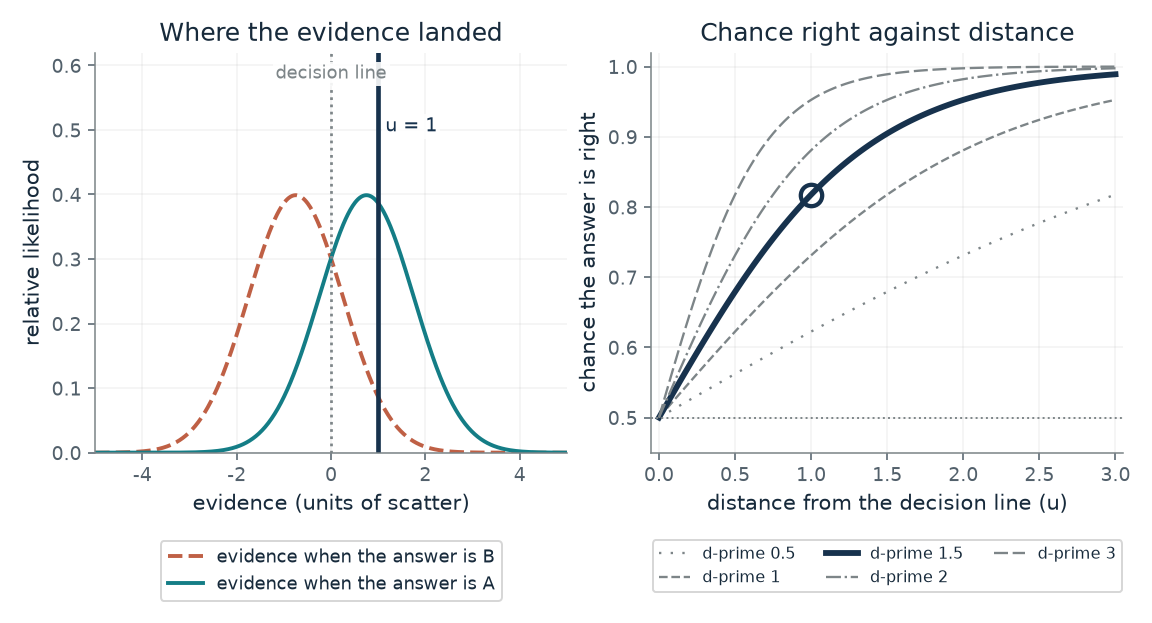

- **Chance the answer is right:** 0.818
- **Chance it is wrong:** 0.182
- **Odds right to wrong:** 4.48
- **d-prime times u:** 1.5

With d-prime 1.5 and evidence 1 units from the line, the model says the answer is right with chance 0.818. At the line itself the chance is one half, and it climbs faster for a larger d-prime.

P(correct | u) = 1/(1 + e^(-d' u)) = 1/(1 + e^(-1.5 x 1)) = 1/(1 + 0.223) = 0.818. Odds right to wrong = e^(d' u) = 4.48.

In [2]:
figure, values, explanation = distance_picture(**{'dprime': 1.5, 'u': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How sure should an answer be, given how far the evidence is from the line?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At d-prime (how well the task separates the cases) = 1.5, Distance from the decision line (u) = 1.0: At d-prime 1.5 and one unit from the line the chance is 0.818, the chapter's 0.82. At zero distance the chance is exactly one half, whatever d-prime is. Move to two units and watch the chance pass 0.9.

**Takeaway:** Confidence should rise with distance from the decision line, and rise faster when the task separates the two cases more cleanly.

**Why it matters:** It gives a reason a stated confidence could carry information at all, and shows what a well-behaved confidence report looks like: at the line it says one half.

**In brains and behavior:** A model of how a judge's sureness could follow the evidence in a task such as Peirce's weights. The chapter does not claim the brain computes this.

**In machines:** A specification for a classifier whose confidence follows the same logistic form; real networks need to be checked against outcomes, not assumed to obey it.

**Where it applies:** Bell-shaped evidence with the same scatter for both cases, equal prior chances, and a decision line halfway between the two typical values. Peirce and Jastrow fitted a different formula to their average marks; this one is a model of how confidence could follow evidence.

**Check your understanding:** At d-prime 3 and distance 1, what is the chance, and what are the odds of right to wrong?

<details><summary>Show the answer</summary>

The odds are e^3 = 20.1, so the chance is 20.1/21.1 = 0.953.

</details>

*Source: Chapter 21, Peirce's marks of sureness tracked accuracy, even the zeros. Book formula. The d-prime 1.5 and distance 1 example, and the chance of 0.82, are the chapter's; every other pair of values is a choice for exploration, not data.*

## C21-D02: Did Peirce's zero marks carry any information?

Peirce marked zero (no preference) on 706 judgments and 436 were right. Could a true hit rate of one half produce that?

If every zero-marked answer had a fixed chance q of being right, the count right would vary around 706 times q with a spread of about 13 or less. A count of 436 sits more than six spreads above 353, the coin-flip expectation. The tail sum adds up every count from 436 to 706 to measure how unusual that is.

$$
P(X\ge 436)=\sum_{k=436}^{706}\binom{706}{k}\,q^{k}(1-q)^{706-k}
$$

**Symbols:** X: the number of right answers among the 706 zero-marked judgments; q: the assumed true chance of a right answer on a zero-marked judgment; C(706, k): the number of ways to choose which k of the 706 were right

**Predict before looking:** Before moving the slider: if the true hit rate on zero marks were 0.6, would 436 right of 706 be rare or ordinary?

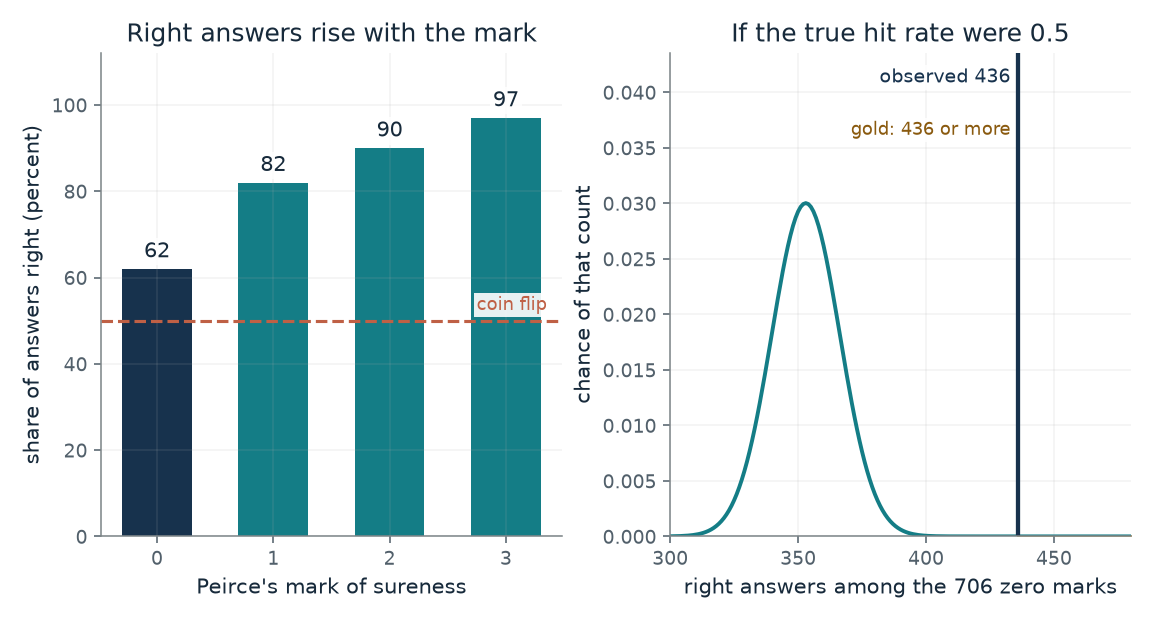

- **Observed share right at mark 0:** 61.8 percent
- **Count expected at this hit rate:** 353
- **Chance of 436 or more:** 2.22e-10
- **Zero marks as a share of 1,125:** 62.8 percent

Of Peirce's 706 zero marks, 436 were right, 61.8 percent. If the true hit rate were 0.5, about 353 would be right, and 436 or more would turn up with chance 2.22e-10. This is a binomial calculation on the printed tallies, not a re-analysis of the 1885 data.

Observed 436/706 = 0.618. Expected count at hit rate 0.5 = 706 x 0.5 = 353. P(X >= 436) = sum over k from 436 to 706 of C(706, k) 0.5^k (1 - 0.5)^(706 - k) = 2.22e-10.

In [3]:
figure, values, explanation = peirce_picture(**{'chance': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="Did Peirce's zero marks carry any information?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Assumed true hit rate on zero marks = 0.5: At a true hit rate of one half, 436 or more right of 706 has chance about 2.2 in 10 billion. The zeros were not coin flips, as the chapter says. The count is ordinary for a rate near 0.62.

**Takeaway:** Even Peirce's marks of no preference were right about 62 percent of the time, which a coin flip makes very unlikely.

**Why it matters:** It is the earliest evidence in the chapter that a judge's sureness, even at its lowest mark, can carry information about being right.

**In brains and behavior:** A person's reported sureness was linked to accuracy. This is a record of reports, not of neural activity, and two people were tested.

**In machines:** The same check applies to a machine: take the cases at its lowest confidence and ask whether it still beats chance.

**Where it applies:** The 706 judgments are treated as independent trials with one hit rate. That is a simplification: they came from one person over a long series. The tally covers two people on one weight task, and shows nothing about how confidence is made.

**Check your understanding:** At a hit rate of 0.6, how many of the 706 would you expect to be right, and is 436 above or below that?

<details><summary>Show the answer</summary>

706 x 0.6 = 423.6 expected; 436 is above it by about 12, which is ordinary: the chance of 436 or more is 0.18.

</details>

*Source: Chapter 21, Peirce's marks of sureness tracked accuracy, even the zeros. The tallies are the chapter's, quoted from Peirce and Jastrow's 1885 footnote: 706 zero marks among 1,125 judgments, 436 right, and 62, 82, 90 and 97 percent right at marks 0 to 3. The binomial tail is the companion's own calculation on those printed counts; the authors did not report it.*

## C21-D03: Can confidence sort perfectly and still be wrong about its numbers?

Ten answers, six right and four wrong. How do sorting and calibration behave as you change the confidence given to each group?

Sorting asks only about the order of the confidences. Calibration asks whether the numbers equal how often answers are right. Rater A has the right order and the wrong scale. Rater B has the right scale and no order. The Brier score punishes both defects, which is why a rater that sorts perfectly can still lose to one that states the base rate.

$$
\text{sorting}=\Pr(c_{\text{right}}>c_{\text{wrong}})+\tfrac12\Pr(c_{\text{right}}=c_{\text{wrong}}),\qquad \operatorname{BS}=\frac1n\sum_i (p_i-y_i)^2
$$

**Symbols:** c_right, c_wrong: the stated confidence on a right answer and on a wrong answer; sorting: chance a right answer gets higher confidence than a wrong one, ties counted half; 0.5 means no advantage; BS: the Brier score, the average squared gap between stated confidence and the outcome (1 right, 0 wrong); lower is better

**Predict before looking:** Rater A gives 0.9 to right answers and 0.8 to wrong ones. Rater B says 0.6 every time. Which has the better sorting score and which the better Brier score?

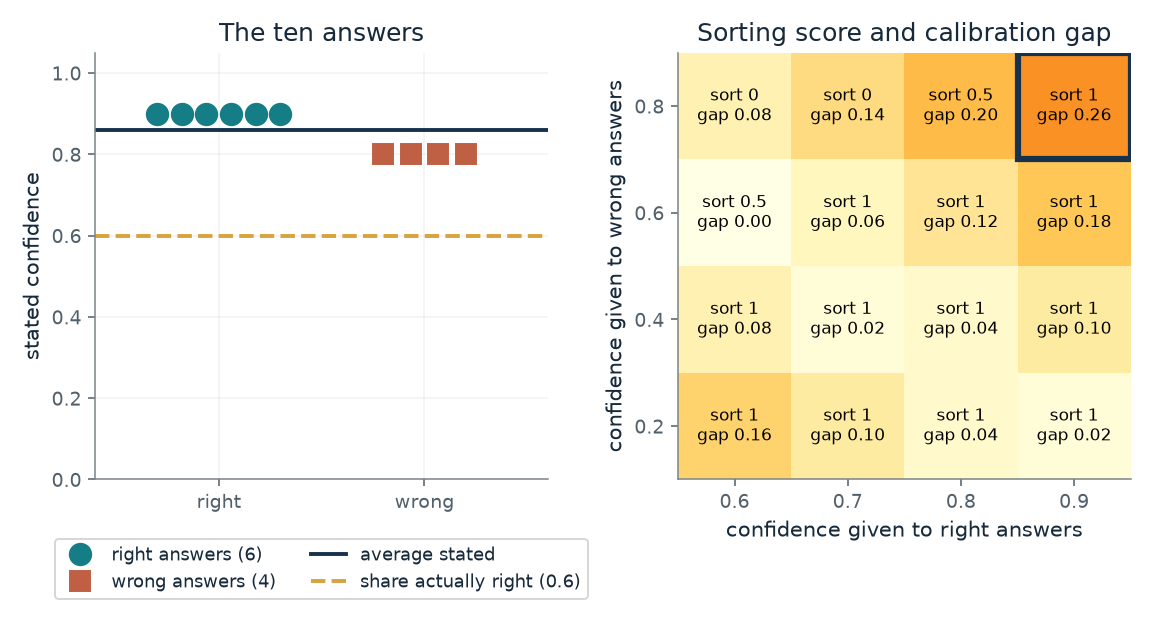

- **Sorting score:** 1
- **Average stated confidence:** 0.86
- **Share actually right:** 0.6
- **Brier score (lower is better):** 0.262

Giving right answers 0.9 and wrong ones 0.8, the sorting score is 1 and the stated numbers average 0.86 against a hit rate of 0.6. Sorting and calibration move separately: the Brier score is 0.262.

Sorting: of the 6 x 4 = 24 right-wrong pairs, a right answer with higher confidence counts 1, a tie 1/2: score 1. Average stated = (6 x 0.9 + 4 x 0.8)/10 = 0.86; hit rate 6/10 = 0.6; gap 0.26. Brier = (6 x (1 - 0.9)^2 + 4 x 0.8^2)/10 = 0.262.

In [4]:
figure, values, explanation = sorting_picture(**{'conf_right': 0.9, 'conf_wrong': 0.8})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can confidence sort perfectly and still be wrong about its numbers?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Confidence given to right answers = 0.9, Confidence given to wrong answers = 0.8: A sorts perfectly (score 1) but states an average of 0.86 against a hit rate of 0.6, and its Brier score is 0.262. Now set 0.6 and 0.6: nothing is sorted (0.5), yet the numbers match the hit rate and the Brier score is 0.24, better than A's.

**Takeaway:** Sorting and calibration are separate checks, and a confidence can pass one while failing the other.

**Why it matters:** A reviewer who can inspect only a fixed share of cases needs sorting. One who acts on a cost threshold needs the numbers to be right. Both checks are needed before trusting a confidence report.

**In brains and behavior:** Peirce's marks were tallied by hit rate at each mark, a sorting-style check. They were never tested for whether a mark stood for a stated chance.

**In machines:** A machine's confidence can be graded on both counts, as Guo and colleagues did for calibration.

**Where it applies:** Every right answer gets one confidence value and every wrong answer another, so the sorting score is 1, 0.5 or 0. Real raters give varied numbers; this reduces the case to its logic.

**Check your understanding:** Give right answers 0.8 and wrong answers 0.2. What are the sorting score and the average stated confidence?

<details><summary>Show the answer</summary>

Sorting is 1. The average stated is (6 x 0.8 + 4 x 0.2)/10 = 0.56, close to the hit rate of 0.6, and the Brier score is 0.04.

</details>

*Source: Chapter 21, One fitted number cut a network's calibration error from 16.53 to 1.26 percent. Constructed example adapted by the book from Fleming and Lau (90 percent on right answers, 80 percent on wrong ones, 60 percent right). The Brier score for the settings is the companion's calculation. The other grid values are choices for exploration.*

## C21-D04: Why does an honest probability score best?

A forecaster believes the chance of rain is 0.7. What does reporting 0.5 or 0.9 cost her, compared with reporting 0.7?

If the event happens with chance b, the expected cost of announcing q is b(1-q)^2 + (1-b)q^2. Expanding gives b(1-b), the irreducible uncertainty, plus (q-b)^2, a penalty that is zero only at q = b. The log-loss curve also bottoms out at q = b, but it climbs steeply as the report nears 0 or 1.

$$
\mathbb{E}[\mathrm{cost}]=b(1-q)^2+(1-b)q^2=b(1-b)+(q-b)^2
$$

**Symbols:** b: the forecaster's true belief about the chance of rain; q: the chance she reports; cost: the squared gap between the report and what happened (1 if it rained, 0 if not), averaged over days

**Predict before looking:** She believes 0.7. Which costs more per day, reporting 0.5 or reporting 0.9?

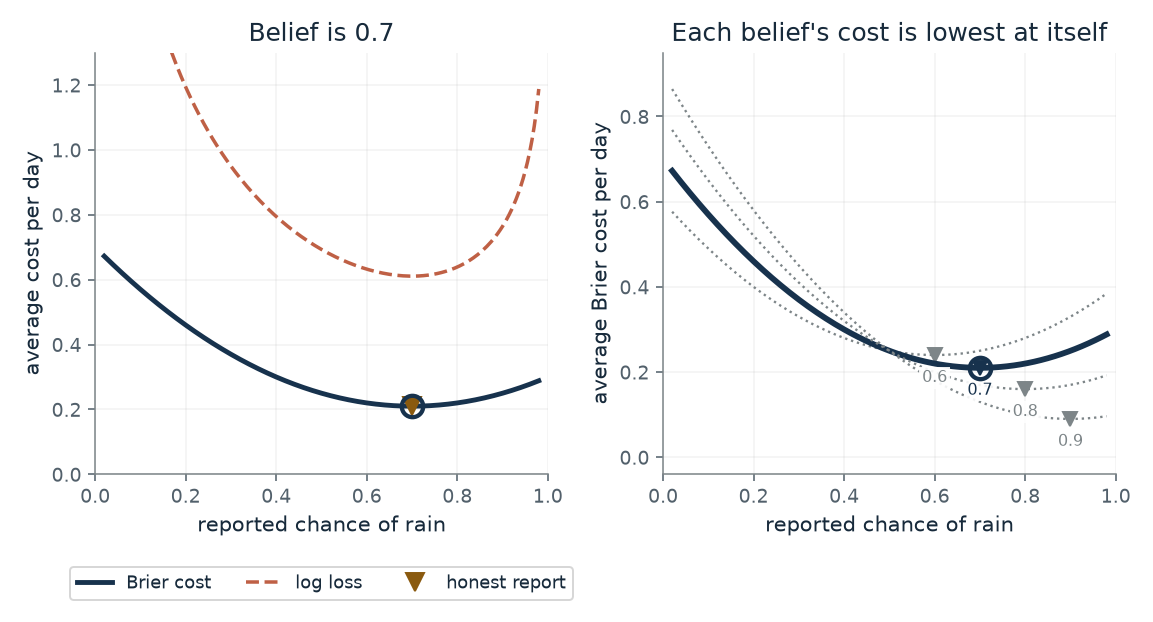

- **Average Brier cost of this report:** 0.21
- **Cost of the honest report:** 0.21
- **Extra cost of shading:** 0
- **Average log loss of this report:** 0.611

A forecaster who believes the chance is 0.7 and reports 0.7 pays 0.21 a day in squared error, against 0.21 for reporting the belief. The extra cost is the squared distance between report and belief, 0.

Cost = 0.7 x (1 - 0.7)^2 + 0.3 x 0.7^2 = 0.21. Honest: 0.7 x 0.3 = 0.21. Cost - honest = (0.7 - 0.7)^2 = 0.

In [5]:
figure, values, explanation = honesty_picture(**{'belief': 0.7, 'report': 0.7})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does an honest probability score best?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Forecaster's true belief = 0.7, Reported chance of rain = 0.9: Reporting 0.9 costs 0.25 a day, against 0.21 for the honest 0.7. Change the report to 0.5 and it costs 0.25 too. Both shadings are 0.2 from her belief, and the extra cost is 0.2 squared, 0.04.

**Takeaway:** Under the Brier score the cheapest report is the real belief, and shading either way adds the square of the shading.

**Why it matters:** A score that rewards hedging or overstatement would teach forecasters, and models, to misreport. This one does not, though it cannot make a system actually hold accurate beliefs.

**In brains and behavior:** Nothing here says a brain scores itself this way.

**In machines:** Machines are trained on log loss, a relative of the Brier score that is also honest but harsher on confident misses. Guo's networks were trained on it and still ended overconfident.

**Where it applies:** The forecaster's belief is accurate, so rain follows it on average. The score is the one-event Brier score; Brier's 1950 version doubled it. Honesty here means the report that minimizes expected cost; it does not show anyone is honest.

**Check your understanding:** For a forecast of 0.99 on an event that does not happen, what are the squared error and the log loss? And for 0.60?

<details><summary>Show the answer</summary>

At 0.99 the true outcome got probability 0.01: squared error 0.99^2 = 0.98, log loss -ln(0.01) = 4.61. At 0.60 the outcome got 0.40: squared error 0.36, log loss -ln(0.4) = 0.92.

</details>

*Source: Chapter 21, Brier's 1950 score for weather forecasters rewards honest probabilities. Constructed example from the chapter: belief 0.7, costs 0.21 for 0.7 and 0.25 for 0.5 or 0.9. The log-loss curve and the algebraic split into belief variance plus squared distance are the companion's additions. The chapter's log-loss check (0.99: 0.98 squared error, 4.61 log loss; 0.60: 0.36, 0.92) is quoted in the check below.*

## C21-D05: Can one number repair a network's overconfidence?

If a classifier's scores are too sharp, what happens to its calibration error and its predictions when every score is divided by one temperature?

The top percentage is the largest of the converted scores. Dividing all scores by T above 1 shrinks the gaps between them, so the top percentage falls, yet the largest score stays the largest, so the predicted class is unchanged. Choosing T so that the stated confidences match the share right in each group gives the fix; in this simulation the matching value is the one the labels were drawn with.

$$
\hat p_k=\frac{e^{z_k/T}}{\sum_j e^{z_j/T}},\qquad \mathrm{ECE}=\sum_{b=1}^{15}\frac{|B_b|}{N}\,\bigl|\operatorname{acc}(B_b)-\operatorname{conf}(B_b)\bigr|
$$

**Symbols:** z_k: the raw score for class k, before conversion to percentages; T: the temperature, one number dividing every score; above 1 spreads the percentages out; ECE: calibration error: the average gap between share right and stated confidence across 15 confidence groups, weighted by group size; B_b, N: the cases in group b, and the total number of cases

**Predict before looking:** If the simulator's own temperature is 2, which scaling temperature do you expect to give the smallest calibration error?

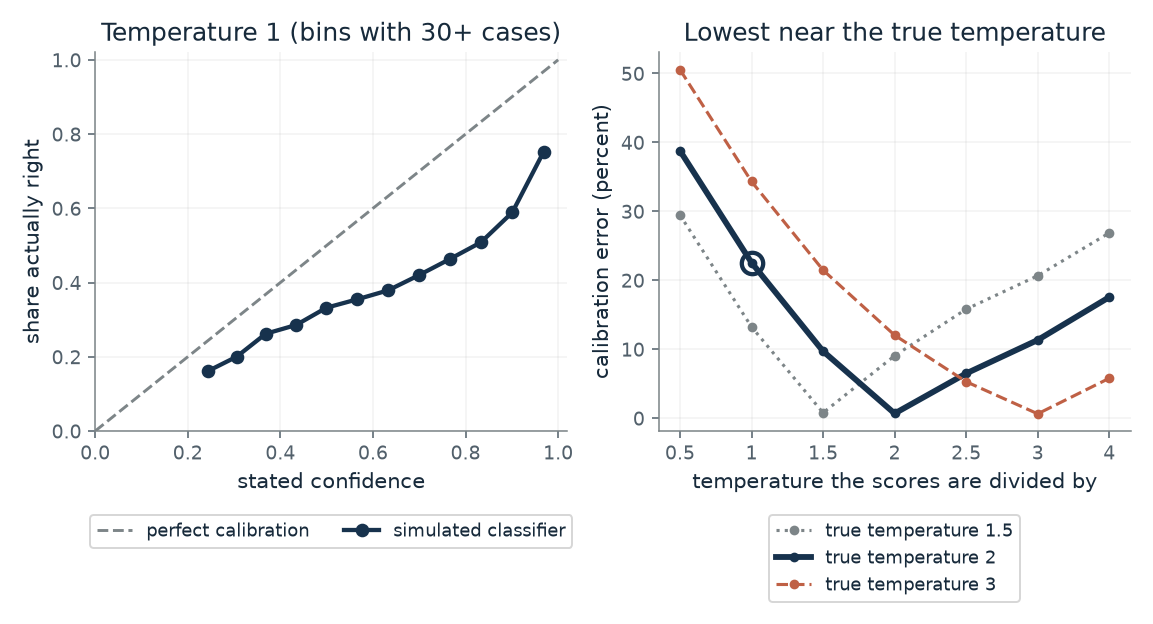

- **Calibration error (percent):** 22.6
- **Average confidence (percent):** 65.8
- **Accuracy (percent):** 43.2
- **Predicted classes changed by scaling:** 0 of 20000

On 20000 simulated cases, dividing the scores by 1 gives calibration error 22.6 percent when the simulator's own temperature is 2. Accuracy stays 43.2 percent and no predicted class changes. A simulation is a construction, not a measurement of any real network.

Confidence = largest of softmax(score/1). Error = sum over 15 equal bins of (cases in bin/20000) x |share right - average confidence| = 0.226. Seed 2026; 10 classes; labels are drawn from softmax(score/2).

In [6]:
figure, values, explanation = temperature_picture(**{'true_temp': 2.0, 'temp': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="Can one number repair a network's overconfidence?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Simulator's own temperature (how overconfident the raw scores are) = 2.0, Temperature the scores are divided by = 2.0: With the scaling temperature equal to the simulator's, 2, the calibration error falls to a fraction of a percent, against a much larger error at temperature 1. Accuracy and every predicted class are exactly as before.

**Takeaway:** Dividing the scores by one fitted number can fix the scale of confidence while leaving every predicted class alone.

**Why it matters:** It shows calibration can be repaired without changing the sorting of cases or the answers. It is also a reminder that the fix is fitted on held-out cases and may fail on different data.

**In brains and behavior:** No study in the chapter claims brains use a rescaling like this.

**In machines:** A post-hoc recalibration of a classifier's scores, fitted on held-out cases. The simulation is a specification of the idea, not a model of any real network.

**Where it applies:** Labels are drawn from softmax(score/true temperature), so the raw softmax is overconfident by construction and the right temperature is known. Real networks have no such clean structure, and the chapter notes the fix slightly hurt on a text collection (Reuters) and assumed one data source. No study here says brains use such a repair.

**Check your understanding:** In the simulation with true temperature 2, does scaling by 4 repair the overconfidence, over-correct it, or do nothing?

<details><summary>Show the answer</summary>

It over-corrects: the stated confidence falls below the share actually right, and the calibration error is larger than at temperature 2. The predicted classes still do not change.

</details>

*Source: Chapter 21, One fitted number cut a network's calibration error from 16.53 to 1.26 percent. Reported result: Guo and colleagues found ResNet-110 on CIFAR-100 had calibration error 16.53 percent, cut to 1.26 percent by one fitted temperature, with predicted classes unchanged. The picture is NOT that experiment: it is a seeded simulation (seed 2026, 20,000 cases, 10 classes) built so that one temperature is exactly right.*

## C21-D06: When a model declines the hard questions, what does its accuracy mean?

A model gets 70 of 100 right. If it declines some questions, how does its accuracy on the rest change?

Of the 70 right answers, the model gives up r by declining and keeps the rest. Its accuracy on the answered cases is the remaining right answers divided by the remaining questions. If the declined cases were right as often as the average, accuracy stays 70 percent while coverage falls. Only declining cases that are mostly wrong raises it.

$$
\text{accuracy on answered}=\frac{70-r}{100-d},\qquad \text{coverage}=\frac{100-d}{100}
$$

**Symbols:** d: the number of questions declined; r: how many of the declined questions the model would have got right; coverage: the share of questions the model actually answered

**Predict before looking:** Suppose the model declines 40 questions and 70 percent of them would have been right, the same as its average. Will its accuracy on the remaining 60 go up, go down or stay?

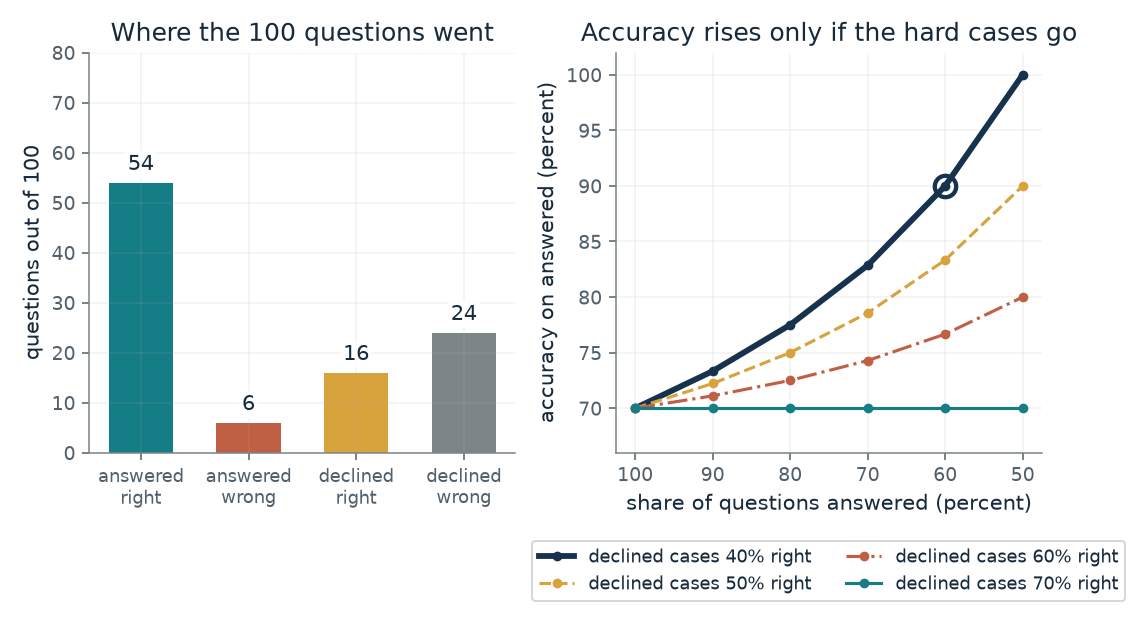

- **Share answered (percent):** 60
- **Accuracy on answered (percent):** 90
- **Right answers given up:** 16
- **Wrong answers avoided:** 24

Declining 40 of 100 questions, with 40 percent of those declined cases right anyway, leaves 54 right of 60 answered, 90 percent, at 60 percent coverage. Accuracy on the answered cases must always be reported with the share answered.

Right among declined = 40 x 0.4 = 16. Right among answered = 70 - 16 = 54. Answered = 100 - 40 = 60. Accuracy = 54/60 = 0.9.

In [7]:
figure, values, explanation = abstain_picture(**{'declined': 40, 'right_share_declined': 0.4})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When a model declines the hard questions, what does its accuracy mean?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Questions declined = 40, Share of the declined that would have been right = 0.4: Declining 40 cases of which 16 (40 percent) would have been right leaves 54 of 60, 90 percent, at 60 percent coverage. Change the declined share to 0.7 and accuracy stays at 70 percent: declining easy cases buys nothing.

**Takeaway:** Declining raises accuracy on the answered cases only if the declined ones were harder, and it always costs coverage.

**Why it matters:** A 90 percent figure means little without the share answered, and without the right answers given up. The same logic applies to a reviewer deciding which cases to send for human checking.

**In brains and behavior:** In Kiani and Shadlen's task, monkeys took a sure bet more often on weak evidence and were more accurate on trials where they passed it up. The authors' account is correlational and low-level; nothing here simulates it.

**In machines:** A model that can decline, graded on answered cases alone, can look better than it is; the chapter's Kadavath paper did not test declining.

**Where it applies:** The number of declines and the share of declined cases that would have been right are set by hand. Not every pair is possible: the declined cases cannot hold more than the 30 wrong answers. Which cases a real model declines is the whole question, and this does not model it.

**Check your understanding:** Decline 20 questions of which 40 percent would have been right. What is accuracy on the answered cases and the coverage?

<details><summary>Show the answer</summary>

8 right are given up, leaving 62 right of 80 answered, 77.5 percent, at 80 percent coverage.

</details>

*Source: Chapter 21, Monkeys with a sure bet and patients with front-of-brain damage. Constructed example: the chapter's imagined model with 70 of 100 right that declines its 40 hardest cases (16 right), giving 54 of 60. The other declines and hit shares are choices for exploration. Kiani and Shadlen's monkeys are not simulated.*

## Bring it to your own question

Ask for the stated confidences and the outcomes on held-out cases. Compute the sorting score (chance a right answer gets higher confidence than a wrong one, ties half) and compare stated confidence with the hit rate in groups of similar confidence. Choose the fix to match the failure: a rescaling for a calibration gap, a better model for weak sorting. When answers are declined, report accuracy together with the share answered. Say what the numbers do not show.

Use the `mmi-ch21-knowing-what-you-know` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.